# Questão 6 - Sistema fuzzy para controle de irrigação

A aplicação escolhida é um controlador que decide por quanto tempo irrigar uma horta. Ele olha para a umidade do solo e para a temperatura do ar e responde com o tempo de irrigação em minutos.

O problema combina com lógica fuzzy porque os conceitos usados por quem cuida da horta são vagos: solo "seco", dia "quente", regar "pouco". Não existe um valor exato em que o solo deixa de ser seco e passa a ser úmido.

O sistema segue o método de Mamdani e foi feito com a biblioteca scikit-fuzzy.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## 1. Variáveis e universos de discurso

**Umidade do solo (entrada):** de 0 a 100 %. Termos: seco, úmido, encharcado.

**Temperatura do ar (entrada):** de 0 a 45 °C. Termos: fria, amena, quente.

**Tempo de irrigação (saída):** de 0 a 60 minutos. Termos: curto, médio, longo.

Os universos cobrem os valores que os sensores podem medir numa horta comum. O limite de 60 minutos é o máximo que o sistema pode deixar a água ligada em um ciclo.

In [2]:
umidade = ctrl.Antecedent(np.arange(0, 101, 1), "umidade")
temperatura = ctrl.Antecedent(np.arange(0, 46, 1), "temperatura")
tempo = ctrl.Consequent(np.arange(0, 61, 1), "tempo", defuzzify_method="centroid")

## 2. Funções de pertinência (fuzzificação)

Os termos das pontas usam funções trapezoidais, porque abaixo ou acima de certo valor a pertinência deve ficar em 1 (um solo com 5 % de umidade é tão seco quanto um com 10 %). Os termos do meio usam funções triangulares, que têm um único ponto de pertinência máxima.

Os conjuntos vizinhos se sobrepõem. É essa sobreposição que faz a saída mudar aos poucos quando a entrada muda.

In [3]:
umidade["seco"] = fuzz.trapmf(umidade.universe, [0, 0, 20, 45])
umidade["umido"] = fuzz.trimf(umidade.universe, [25, 50, 75])
umidade["encharcado"] = fuzz.trapmf(umidade.universe, [55, 80, 100, 100])

temperatura["fria"] = fuzz.trapmf(temperatura.universe, [0, 0, 12, 22])
temperatura["amena"] = fuzz.trimf(temperatura.universe, [15, 24, 33])
temperatura["quente"] = fuzz.trapmf(temperatura.universe, [27, 35, 45, 45])

tempo["curto"] = fuzz.trapmf(tempo.universe, [0, 0, 5, 20])
tempo["medio"] = fuzz.trimf(tempo.universe, [10, 30, 50])
tempo["longo"] = fuzz.trapmf(tempo.universe, [40, 52, 60, 60])

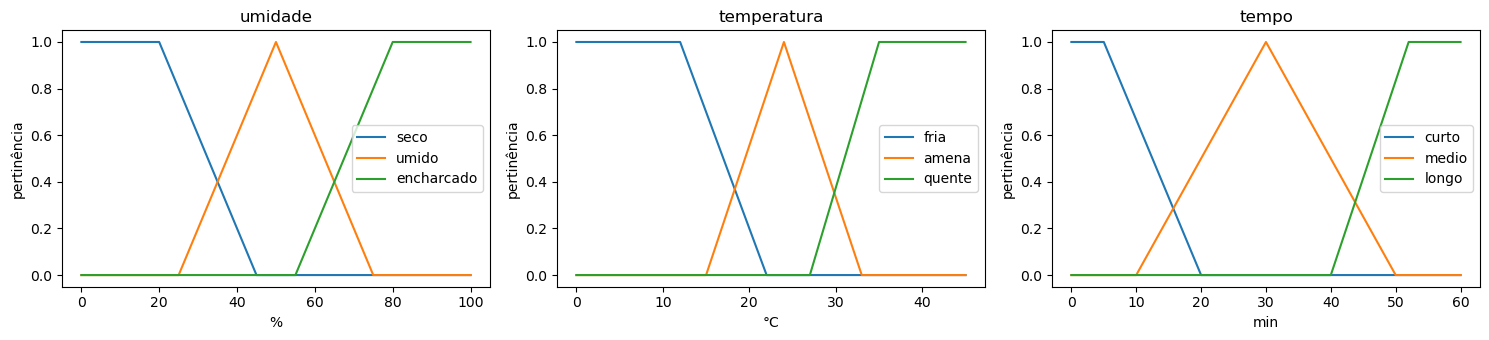

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.5))
for eixo, var, unidade in zip(eixos, [umidade, temperatura, tempo], ["%", "°C", "min"]):
    for nome, termo in var.terms.items():
        eixo.plot(var.universe, termo.mf, label=nome)
    eixo.set_title(var.label)
    eixo.set_xlabel(unidade)
    eixo.set_ylabel("pertinência")
    eixo.legend()
plt.tight_layout()
plt.show()

## 3. Base de regras

Com três termos em cada entrada, são nove combinações possíveis. Cada combinação tem uma regra, então a base é completa: qualquer leitura dos sensores ativa pelo menos uma regra.

A ideia das regras é simples: quanto mais seco e mais quente, mais tempo de irrigação. Com solo encharcado a irrigação é sempre curta.

In [5]:
matriz = {
    ("seco", "fria"): "medio",
    ("seco", "amena"): "longo",
    ("seco", "quente"): "longo",
    ("umido", "fria"): "curto",
    ("umido", "amena"): "medio",
    ("umido", "quente"): "medio",
    ("encharcado", "fria"): "curto",
    ("encharcado", "amena"): "curto",
    ("encharcado", "quente"): "curto",
}

regras = [ctrl.Rule(umidade[u] & temperatura[t], tempo[s]) for (u, t), s in matriz.items()]

pd.Series(matriz).unstack().loc[["seco", "umido", "encharcado"], ["fria", "amena", "quente"]]

,fria,amena,quente
seco,medio,longo,longo
umido,curto,medio,medio
encharcado,curto,curto,curto


## 4. Inferência de Mamdani passo a passo

Antes de usar o simulador pronto, a inferência é feita aqui manualmente para uma leitura: umidade de 35 % e temperatura de 30 °C.

**Passo 1, fuzzificação:** calcular o grau de pertinência de cada entrada em cada termo.

In [6]:
u_lido, t_lido = 35, 30

grau_u = {n: fuzz.interp_membership(umidade.universe, umidade[n].mf, u_lido) for n in umidade.terms}
grau_t = {n: fuzz.interp_membership(temperatura.universe, temperatura[n].mf, t_lido) for n in temperatura.terms}

print("Umidade", u_lido, "% ->", {k: round(float(v), 3) for k, v in grau_u.items()})
print("Temperatura", t_lido, "°C ->", {k: round(float(v), 3) for k, v in grau_t.items()})

Umidade 35 % -> {'seco': 0.4, 'umido': 0.4, 'encharcado': 0.0}
Temperatura 30 °C -> {'fria': 0.0, 'amena': 0.333, 'quente': 0.375}


**Passo 2, avaliação das regras:** o conectivo E é calculado pelo mínimo entre os graus dos dois antecedentes. O resultado é a força de disparo da regra.

In [7]:
disparo = pd.DataFrame(
    [
        {"umidade": u, "temperatura": t, "saída": s, "força": round(float(min(grau_u[u], grau_t[t])), 3)}
        for (u, t), s in matriz.items()
    ]
)
disparo[disparo["força"] > 0]

,umidade,temperatura,saída,força
1,seco,amena,longo,0.333
2,seco,quente,longo,0.375
4,umido,amena,medio,0.333
5,umido,quente,medio,0.375


**Passo 3, implicação:** o conjunto de saída de cada regra é cortado na altura da força de disparo (mínimo).

**Passo 4, agregação:** os conjuntos cortados são unidos pelo máximo, formando um único conjunto fuzzy de saída.

In [8]:
agregado = np.zeros_like(tempo.universe, dtype=float)
for (u, t), s in matriz.items():
    forca = min(grau_u[u], grau_t[t])
    agregado = np.fmax(agregado, np.fmin(forca, tempo[s].mf))

**Passo 5, defuzzificação:** o conjunto agregado é transformado em um número. O método usado é o centroide, que calcula o centro de gravidade da área. Ele foi escolhido porque leva em conta todas as regras disparadas e gera uma saída que varia de forma suave.

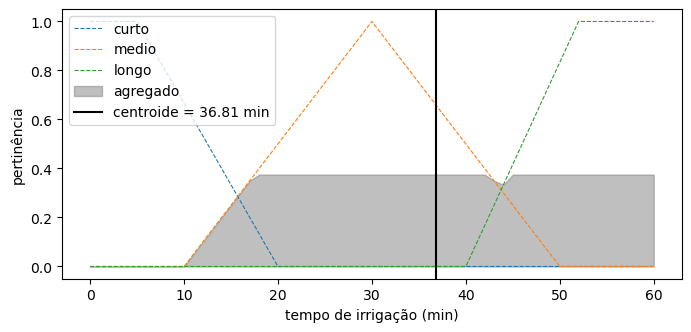

In [9]:
saida_manual = fuzz.defuzz(tempo.universe, agregado, "centroid")

plt.figure(figsize=(8, 3.5))
for nome, termo in tempo.terms.items():
    plt.plot(tempo.universe, termo.mf, "--", linewidth=0.8, label=nome)
plt.fill_between(tempo.universe, agregado, alpha=0.5, color="gray", label="agregado")
plt.axvline(saida_manual, color="black", label=f"centroide = {saida_manual:.2f} min")
plt.xlabel("tempo de irrigação (min)")
plt.ylabel("pertinência")
plt.legend()
plt.show()

## 5. Mesmo cálculo com o simulador do scikit-fuzzy

O `ControlSystem` faz os cinco passos de uma vez. O resultado deve ser igual ao do cálculo manual.

In [10]:
sistema = ctrl.ControlSystem(regras)
simulador = ctrl.ControlSystemSimulation(sistema)


def irrigar(u, t):
    simulador.input["umidade"] = u
    simulador.input["temperatura"] = t
    simulador.compute()
    return simulador.output["tempo"]


print(f"Manual:    {saida_manual:.2f} min")
print(f"Simulador: {irrigar(u_lido, t_lido):.2f} min")

Manual:    36.81 min
Simulador: 36.80 min


## 6. Testes com outras leituras

In [11]:
cenarios = [(10, 38), (35, 30), (50, 24), (50, 10), (65, 36), (90, 40)]
pd.DataFrame(
    [{"umidade (%)": u, "temperatura (°C)": t, "tempo (min)": round(irrigar(u, t), 1)} for u, t in cenarios]
)

,umidade (%),temperatura (°C),tempo (min)
0,10,38,52.6
1,35,30,36.8
2,50,24,30.0
3,50,10,7.0
4,65,36,23.1
5,90,40,7.0


As respostas seguem o esperado. Solo muito seco em dia quente recebe a maior irrigação. Solo encharcado recebe pouco tempo mesmo com calor. Nos casos intermediários a saída fica entre os termos, o que mostra o efeito de várias regras disparando ao mesmo tempo.

## 7. Comparação entre métodos de defuzzificação

O mesmo conjunto agregado do passo 4 pode ser defuzzificado de outras formas.

In [12]:
metodos = {
    "centroid": "centroide",
    "bisector": "bissetor",
    "mom": "média dos máximos",
    "som": "menor dos máximos",
    "lom": "maior dos máximos",
}
pd.DataFrame(
    [{"método": nome, "tempo (min)": round(float(fuzz.defuzz(tempo.universe, agregado, m)), 2)} for m, nome in metodos.items()]
)

,método,tempo (min)
0,centroide,36.81
1,bissetor,36.79
2,média dos máximos,38.78
3,menor dos máximos,18.00
4,maior dos máximos,60.00


O centroide e o bissetor consideram a área inteira e dão valores próximos. Os métodos baseados nos máximos olham só para a regra mais forte e ignoram as outras, por isso a saída deles dá saltos quando a regra dominante muda. Para um controlador de irrigação o centroide é a melhor opção.

## 8. Superfície de controle

A superfície mostra a saída do sistema para todas as combinações de entrada.

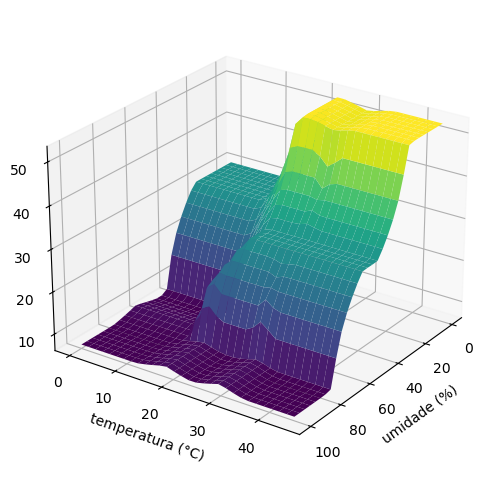

In [13]:
us = np.linspace(0, 100, 30)
ts = np.linspace(0, 45, 30)
U, T = np.meshgrid(us, ts)
Z = np.array([[irrigar(u, t) for u in us] for t in ts])

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(U, T, Z, cmap="viridis")
ax.set_xlabel("umidade (%)")
ax.set_ylabel("temperatura (°C)")
ax.set_zlabel("tempo (min)")
ax.view_init(25, 35)
plt.show()

## 9. Discussão

A modelagem foi feita em quatro etapas: escolha das variáveis e dos universos, definição dos termos e das funções de pertinência, escrita das regras e escolha dos operadores.

A inferência usa o método de Mamdani: mínimo para o E, mínimo para a implicação, máximo para a agregação e centroide para a defuzzificação. A vantagem desse método é que a saída de cada regra é um conjunto fuzzy, então as regras ficam fáceis de ler e de explicar. A desvantagem é o custo da defuzzificação, que precisa percorrer todo o universo de saída.

A superfície de controle é contínua e não tem degraus. Isso mostra a principal diferença para um sistema de regras comum, em que uma pequena mudança na umidade poderia trocar de uma vez o tempo de irrigação de curto para longo.

O ponto fraco do sistema é que as funções de pertinência e as regras foram definidas por bom senso, sem dados reais de uma horta. Em uso real elas precisariam ser ajustadas com a ajuda de um especialista ou com medições.